# App-22 (C#) — Sélection empirique d'algorithmes : trois jeux, 13 familles conceptuelles, 14 étiquettes mesurées

**Navigation** : [<< App-21 VoiceLeading](App-21-VoiceLeading-Python.ipynb) | [Index](README.md) | [App-23 PRESENT >>](App-23-PRESENT-Differential-Cryptanalysis-SAT-Python.ipynb)

**Série** : Search / Part3-Cas-pratiques — jumeau .NET du carnet Python [App-22-AlgorithmSelection-Python](App-22-AlgorithmSelection-Python.ipynb).

**Durée estimée** : ~45 min.

**Prérequis** : [MGS-16 AlgorithmSelection](../Part4-Metaheuristics/MGS-16-AlgorithmSelection.ipynb) (problème de sélection de Rice, No Free Lunch), [Sudoku-18b](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb) (comparaison statistique honnête), notions de C#.

## Hommage à un travail étudiant

Ce carnet distille et replace dans un **cadre plus large** le *Benchmark cross-paradigme de solveurs de jeux* réalisé en solo par **Théodore Deguest** (sujet **L4**, cours *Intelligence Symbolique*, EPITA SCIA) : [PR #42](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/pull/42), projet [L4-Benchmark-Cross-Paradigm](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/tree/main/L4-Benchmark-Cross-Paradigm).

Son geste intellectuel : faire **courir ensemble** — sur un protocole commun et avec des métriques uniformes — des paradigmes de résolution hétérogènes (recherche exacte, CSP/CP-SAT, SAT/SMT, métaheuristique, recherche adversariale, théorie de l'information) sur trois jeux : **Sudoku**, **Puissance 4** et **Wordle**. Le défi n'est pas d'aligner trois solveurs sur un même problème, mais de comparer ce qui, par construction, **ne se compare pas directement** : un nœud de Dancing Links, une décision CP-SAT, une évaluation de solution génétique et une partie de MCTS ne sont pas la même unité de travail.

Le cadre que ce carnet ajoute : le **problème de sélection d'algorithmes** de **Rice (1976)** et le théorème **No Free Lunch** de **Wolpert & Macready (1997)**, au croisement de trois arcs déjà enseignés dans CoursIA : comparer honnêtement des solveurs ([Sudoku-18/18b](../../Sudoku/Sudoku-18-Comparison-Python.ipynb)), caractériser puis sélectionner ([MGS-15](../Part4-Metaheuristics/MGS-15-LandscapeAnalysis.ipynb) → [MGS-16](../Part4-Metaheuristics/MGS-16-AlgorithmSelection.ipynb)), et décider sous plusieurs attributs ([DecInfer-03](../../Probas/DecisionTheory/DecInfer/DecInfer-03-Multi-Attribute.ipynb)). Ici, ils deviennent un **cas d'application vivant** : trois terrains, des familles qui ne partagent ni leur représentation, ni leur unité de coût, ni leur définition du succès. La carte complète est donc **instance → représentation → algorithme → configuration/budget → métrique → décision**.

> **Attribution et licence.** Les trois CSV historiques (`{sudoku,connect_four,wordle}_results.csv`) viennent de Théodore Deguest et sont copiés depuis `results/` de sa PR #42, sous **licence MIT** (copyright 2026, « The 2026-Epita-Intelligence-Symbolique contributors »). Le quatrième CSV (`wordle_repeated_results.csv`) est une **dérivation CoursIA** obtenue en rejouant son code inchangé selon le protocole documenté dans `SOURCE.md`. Toute l'analyse de ce notebook est nouvelle. Aucun solveur étudiant n'est recopié : ils restent dans le dépôt source, référencé et testé.

## Pourquoi un jumeau C# ?

Le carnet Python s'appuie sur `pandas`, `numpy` et `matplotlib`. Ce jumeau **refait toute l'analyse en BCL pure** — aucune dépendance externe : lecture CSV écrite à la main, agrégations par groupe, dominance de Pareto, normalisation min-max, bootstrap déterministe et figure **SVG inline** générée par le code. Le but pédagogique est double : montrer que la sélection d'algorithmes ne doit rien à une bibliothèque particulière, et rendre chaque étape de calcul **lisible dans le code** plutôt que déléguée à un `groupby` opaque.

Les **données sont identiques** (les quatre mêmes CSV, lus depuis `data/app22-cross-paradigm/`) : les deux carnets doivent aboutir aux mêmes vainqueurs, aux mêmes fronts et aux mêmes classements. Les écarts de bibliothèque sont documentés dans le registre de parité des jumeaux.

## Comment lire ce carnet

Ce carnet fait deux choses à la fois : il **ré-analyse** un benchmark étudiant et il en **tire une méthode de sélection d'algorithmes**. Les deux se lisent dans cet ordre.

**Le chemin de lecture** — quatre jalons, chacun bâti sur le précédent :

1. **§2 — Le contrat expérimental** : ce que contiennent les données, et ce qu'elles ne comparent pas d'emblée.
2. **§3 — Les profils intra-jeu** : ce que chaque famille optimise réellement, jeu par jeu.
3. **§4 — Les frontières de Pareto** : pourquoi un podium unique serait un choix caché — et la figure qui rend le compromis visible.
4. **§5 — La sélection sous préférences** : le point de bascule entre deux préférences, mesuré.

**§6** referme avec la **traçabilité**. Les **trois exercices** sont posés en §3, §4 et §5, chacun juste après la lecture de son résultat.

### Les annexes

- **Annexe A — Objectifs et compétences visées**.
- **Annexe B — Une moyenne n'est pas une preuve** : les deux niveaux d'incertitude (bootstrap inter-instance, répétition multi-seed).
- **Annexe C — `nodes_explored`** : pourquoi cette colonne ne compte pas la même chose d'une famille à l'autre.
- **Annexe D — Mesurer, choisir, certifier**.
- **Annexe E — Limites honnêtes**.
- **Annexe F — Sources**.

## 1. Transmission : ce qui vient de l'étudiant, ce qui vient de CoursIA

| Brique | Origine | Ce qui est fourni ici |
|---|---|---|
| **Solveurs** (backtracking±MRV, Dancing Links, CP-SAT, SMT, GA, recuit simulé ; minimax, alpha-beta, MCTS, baseline ; élimination bayésienne, entropie, CSP) | **Théodore Deguest** | Référencés et testés, **non recopiés** ; liens vers le dépôt source |
| **Protocole expérimental** (instances, timeouts 120 s, parallélisation, métriques) | Théodore Deguest | Récapitulé, non modifié |
| **Données historiques** (`results/*.csv`) | Théodore Deguest | Trois CSV copiés dans `data/app22-cross-paradigm/` sous licence MIT |
| **Données répétées Wordle** | Code et instances de Théodore ; protocole/collecte **CoursIA** | 45 observations dérivées, provenance séparée dans `SOURCE.md` |
| **Analyse** (profils, Pareto, sélection sous préférences, limites) | **CoursIA** | Nouvelle, ce carnet — et réimplémentée en BCL côté C# |
| **Cadre** (Rice 1976, No Free Lunch) | CoursIA | Rappel de [MGS-16](../Part4-Metaheuristics/MGS-16-AlgorithmSelection.ipynb), appliqué ici |

**Traçabilité de l'hommage.** La citation exacte à retenir : *« Benchmark cross-paradigme de solveurs de jeux »*, Théodore Deguest, sujet L4, cours Intelligence Symbolique EPITA SCIA, PR #42. Le dépôt source est sous licence MIT collective : la ré-analyse et la redistribution des **données** sont permises, à condition de conserver le copyright et la mention de licence (voir `data/app22-cross-paradigm/`) — la **ré-écriture d'analyse** en est une ré-utilisation légitime.

### Ce qui existait déjà — et ce que Théodore déplace

CoursIA possède déjà un benchmark multi-solveurs sur un terrain : [Sudoku-18](../../Sudoku/Sudoku-18-Comparison-Python.ipynb) compare plusieurs philosophies derrière une grille commune, et [Sudoku-18b](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb) montre pourquoi moyenne, variance, intervalle bootstrap et tests appariés doivent rester ensemble. **L'apport de Théodore n'est donc pas « comparer des solveurs Sudoku »**. Il généralise ce geste à **trois terrains** et fait apparaître une difficulté nouvelle : les familles changent aussi la **représentation** et le sens des métriques.

Cette extension rejoint [MGS-21-Représentation-vs-Algorithme](../Part4-Metaheuristics/MGS-21-Representation-vs-Algorithme.ipynb) : choisir DLX, CP-SAT, SMT, MCTS ou entropie, ce n'est pas seulement changer d'algorithme, c'est changer l'objet sur lequel on raisonne.

## 2. Le contrat expérimental étudiant

Avant de raisonner, **charger les données et vérifier leur contrat**.

Le code ci-dessous pose deux briques que tout le reste réutilise : un **lecteur CSV du BCL** (séparateur virgule, guillemets doublés) et une petite table `Frame` qui garde l'en-tête et les lignes. Aucune bibliothèque de données : le contrat se vérifie en lisant les colonnes, pas en les supposant.

In [1]:
using System;
using System.Collections.Generic;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Text;

// Toutes les conversions et tous les affichages numériques passent par la culture
// invariante : les CSV utilisent le point décimal, quelle que soit la machine.
const NumberStyles STYLE = NumberStyles.Float;

/// Table texte minimale : en-tête + lignes de cellules chaînes.
public sealed class Frame
{
    public readonly string[] Columns;
    public readonly List<string[]> Rows;

    public Frame(string[] columns, List<string[]> rows) { Columns = columns; Rows = rows; }

    public bool Has(string name) => Array.IndexOf(Columns, name) >= 0;

    public int Col(string name)
    {
        int i = Array.IndexOf(Columns, name);
        if (i < 0) throw new ArgumentException("colonne absente : " + name);
        return i;
    }

    public double Num(int row, string col)
    {
        var s = Rows[row][Col(col)];
        return string.IsNullOrWhiteSpace(s)
            ? double.NaN
            : double.Parse(s, STYLE, CultureInfo.InvariantCulture);
    }

    public double Bool(int row, string col) => Rows[row][Col(col)] == "True" ? 1.0 : 0.0;
}

/// Lecteur CSV du BCL : séparateur virgule, guillemets doublés, lignes vides ignorées.
public static class Csv
{
    public static Frame Read(string path)
    {
        string[] header = null;
        var rows = new List<string[]>();
        foreach (var line in File.ReadAllLines(path))
        {
            if (string.IsNullOrWhiteSpace(line)) continue;
            var cells = SplitLine(line);
            if (header == null) { header = cells; continue; }
            rows.Add(cells);
        }
        return new Frame(header, rows);
    }

    static string[] SplitLine(string line)
    {
        var cells = new List<string>();
        var cur = new StringBuilder();
        bool quoted = false;
        for (int i = 0; i < line.Length; i++)
        {
            char ch = line[i];
            if (quoted)
            {
                if (ch == '"' && i + 1 < line.Length && line[i + 1] == '"') { cur.Append('"'); i++; }
                else if (ch == '"') quoted = false;
                else cur.Append(ch);
            }
            else if (ch == '"') quoted = true;
            else if (ch == ',') { cells.Add(cur.ToString()); cur.Clear(); }
            else cur.Append(ch);
        }
        cells.Add(cur.ToString());
        return cells.ToArray();
    }
}

// Ancrage des données : on remonte depuis le cwd et on essaie les chemins relatifs usuels,
// pour que le carnet fonctionne depuis son dossier comme depuis la racine du dépôt.
static string FindDataDir()
{
    var roots = new List<string>();
    var d = new DirectoryInfo(Directory.GetCurrentDirectory());
    for (int i = 0; i < 6 && d != null; i++) { roots.Add(d.FullName); d = d.Parent; }
    var relatives = new[]
    {
        Path.Combine("data", "app22-cross-paradigm"),
        Path.Combine("MyIA.AI.Notebooks", "Search", "Part3-Cas-pratiques", "data", "app22-cross-paradigm"),
        Path.Combine("Search", "Part3-Cas-pratiques", "data", "app22-cross-paradigm")
    };
    foreach (var root in roots)
        foreach (var rel in relatives)
        {
            var cand = Path.Combine(root, rel);
            if (File.Exists(Path.Combine(cand, "sudoku_results.csv"))) return cand;
        }
    return Path.Combine(Directory.GetCurrentDirectory(), "data", "app22-cross-paradigm");
}

var DATA = FindDataDir();
var games = new[] { "sudoku", "connect_four", "wordle" };
var frames = games.ToDictionary(g => g, g => Csv.Read(Path.Combine(DATA, g + "_results.csv")));

Console.WriteLine("Répertoire de données : data/app22-cross-paradigm");
Console.WriteLine();
foreach (var g in games)
{
    var df = frames[g];
    int familles = df.Rows.Select(r => r[df.Col("paradigm")]).Distinct().Count();
    int instances = df.Rows.Select(r => r[df.Col("instance_id")]).Distinct().Count();
    Console.WriteLine($"{g,-14} {df.Rows.Count,4} lignes  |  {df.Columns.Length} colonnes  |  {familles} familles  |  {instances} instances");
}
Console.WriteLine();
Console.WriteLine("--- Contrats de schéma (colonnes communes / spécifiques) ---");
var commun = new HashSet<string>(frames[games[0]].Columns);
foreach (var g in games.Skip(1)) commun.IntersectWith(frames[g].Columns);
Console.WriteLine("Colonnes communes aux trois : " + string.Join(", ", commun.OrderBy(c => c, StringComparer.Ordinal)));
foreach (var g in games)
{
    var spec = frames[g].Columns.Where(c => !commun.Contains(c)).ToArray();
    Console.WriteLine($"  {g} : spécifiques -> {(spec.Length == 0 ? "(aucune)" : "[" + string.Join(", ", spec) + "]")}");
}

Répertoire de données : data/app22-cross-paradigm


sudoku          210 lignes  |  10 colonnes  |  7 familles  |  30 instances


connect_four     35 lignes  |  10 colonnes  |  4 familles  |  10 instances


wordle          120 lignes  |  9 colonnes  |  3 familles  |  40 instances


--- Contrats de schéma (colonnes communes / spécifiques) ---


Colonnes communes aux trois : difficulty, game, instance_id, nodes_explored, paradigm, peak_memory_mb, solution_quality, success, time_seconds


  sudoku : spécifiques -> [extra_budget_exceeded]


  connect_four : spécifiques -> [extra_winner]


  wordle : spécifiques -> (aucune)


Le tableau ci-dessus matérialise déjà une première limite : les trois fichiers partagent un **noyau commun** (`game, paradigm, instance_id, difficulty, success, time_seconds, peak_memory_mb, nodes_explored, solution_quality`) mais chacun ajoute **une colonne spécifique** (`extra_budget_exceeded` pour Sudoku, `extra_winner` pour Puissance 4). Le schéma est **uniforme par intention, hétérogène par détail** — la comparabilité doit donc se construire, pas se supposer.

**Un mot sur le décompte.** Le README étudiant annonce **13 solveurs/familles** (6 Sudoku — backtracking et MRV groupés —, 4 Puissance 4 dont le baseline, 3 Wordle). Les CSV portent **14 étiquettes de paradigme** distinctes, car `backtracking` et `backtracking_mrv` sont deux lignes séparées. Ce petit écart compte : il illustre qu'un « solveur » peut être décrit à deux grains, et que la **définition** de la population fait partie du contrat expérimental.

On vérifie maintenant la répartition des familles et des difficultés, pour ne pas comparer des populations différentes.

In [2]:
/// Inventaire de contrôle : familles (paradigmes) et niveaux de difficulté
/// présents dans les CSV de chaque jeu — vérifier que les comparaisons de la
/// suite portent bien sur un terrain commun avant de lire les classements.
foreach (var g in games)
{
    var df = frames[g];
    Console.WriteLine($"===== {g} : familles et difficultés =====");
    foreach (var grp in df.Rows.GroupBy(r => r[df.Col("paradigm")]).OrderBy(x => x.Key, StringComparer.Ordinal))
    {
        var diffs = grp.Select(r => r[df.Col("difficulty")]).Distinct().OrderBy(x => x, StringComparer.Ordinal);
        Console.WriteLine($"  {grp.Key,-24} n={grp.Count(),3}  difficultés=[{string.Join(", ", diffs)}]");
    }
    Console.WriteLine();
}

===== sudoku : familles et difficultés =====


  backtracking             n= 30  difficultés=[diabolical, easy, medium_hard]


  backtracking_mrv         n= 30  difficultés=[diabolical, easy, medium_hard]


  cp_sat                   n= 30  difficultés=[diabolical, easy, medium_hard]


  dancing_links            n= 30  difficultés=[diabolical, easy, medium_hard]


  genetic                  n= 30  difficultés=[diabolical, easy, medium_hard]


... (7 outputs left out)

===== wordle : familles et difficultés =====


  bayesian_elimination     n= 40  difficultés=[5, 6, 7, 8]


  csp                      n= 40  difficultés=[5, 6, 7, 8]


  entropy                  n= 40  difficultés=[5, 6, 7, 8]


## 3. Profils intra-jeu : succès, coût relatif, qualité, répétitions

On agrège par famille **dans chaque jeu**, pour faire apparaître ce que chaque paradigme optimise réellement. Les durées absolues dépendent de la machine d'exécution du benchmark ; on parle donc surtout en **ratios** (`rel_time`, `rel_mem` : 1 = meilleur de son jeu) et en **taux**, jamais en secondes dans la prose.

En C#, l'agrégation s'écrit explicitement : on groupe les **indices de lignes** (et non les lignes elles-mêmes, ce qui rendrait la lecture des colonnes ambiguë), puis on calcule les moyennes colonne par colonne. `solution_quality` est **ignorée quand elle est vide** : sur Sudoku, les solveurs exacts ne la renseignent pas.

In [3]:
/// Une ligne de profil : ce qu'une famille optimise réellement dans un jeu donné.
public sealed class ProfileRow
{
    public string Paradigm;
    public int Instances;
    public int N;
    public double SuccessRate;
    public double MeanTime;
    public double MeanMem;
    public double MeanNodes;
    public double MeanQuality;   // NaN si la colonne est absente ou vide
    public bool HasQuality;
    public double RelTime;
    public double RelMem;
}

static void Fmt(double v) { }

static string N(double v, string fmt = "F3")
    => double.IsNaN(v) ? "NaN" : v.ToString(fmt, CultureInfo.InvariantCulture);

static double MeanOrNaN(IEnumerable<double> values)
{
    var v = values.Where(x => !double.IsNaN(x)).ToArray();
    return v.Length == 0 ? double.NaN : v.Average();
}

static List<ProfileRow> Profile(Frame df)
{
    var rows = new List<ProfileRow>();
    var groups = Enumerable.Range(0, df.Rows.Count)
        .GroupBy(i => df.Rows[i][df.Col("paradigm")])
        .OrderBy(g => g.Key, StringComparer.Ordinal);
    foreach (var grp in groups)
    {
        var idx = grp.ToArray();
        var pr = new ProfileRow
        {
            Paradigm = grp.Key,
            N = idx.Length,
            Instances = idx.Select(i => df.Rows[i][df.Col("instance_id")]).Distinct().Count(),
            SuccessRate = idx.Average(i => df.Bool(i, "success")),
            MeanTime = idx.Average(i => df.Num(i, "time_seconds")),
            MeanMem = idx.Average(i => df.Num(i, "peak_memory_mb")),
            MeanNodes = idx.Average(i => df.Num(i, "nodes_explored")),
        };
        if (df.Has("solution_quality"))
        {
            pr.MeanQuality = MeanOrNaN(idx.Select(i => df.Num(i, "solution_quality")));
            pr.HasQuality = !double.IsNaN(pr.MeanQuality);
        }
        else
        {
            pr.MeanQuality = double.NaN;
        }
        rows.Add(pr);
    }
    double tMin = rows.Min(p => p.MeanTime);
    double mMin = rows.Min(p => p.MeanMem);
    foreach (var p in rows)
    {
        p.RelTime = p.MeanTime > 0 ? tMin / p.MeanTime : double.NaN;
        p.RelMem = p.MeanMem > 0 ? mMin / p.MeanMem : double.NaN;
    }
    return rows;
}

static void PrintProfiles(List<ProfileRow> prof)
{
    bool q = prof.Any(p => p.HasQuality);
    var header = new List<string>
    {
        "paradigm".PadRight(22), "instances".PadLeft(9), "n".PadLeft(3),
        "success_rate".PadLeft(12), "mean_time".PadLeft(12), "mean_mem".PadLeft(10),
        "mean_nodes".PadLeft(12)
    };
    if (q) header.Add("mean_quality".PadLeft(12));
    header.Add("rel_time".PadLeft(9));
    header.Add("rel_mem".PadLeft(8));
    Console.WriteLine(string.Join("  ", header));
    foreach (var p in prof)
    {
        var cells = new List<string>
        {
            p.Paradigm.PadRight(22), p.Instances.ToString().PadLeft(9), p.N.ToString().PadLeft(3),
            N(p.SuccessRate).PadLeft(12), N(p.MeanTime).PadLeft(12), N(p.MeanMem).PadLeft(10),
            N(p.MeanNodes).PadLeft(12)
        };
        if (q) cells.Add((p.HasQuality ? N(p.MeanQuality) : "NaN").PadLeft(12));
        cells.Add(N(p.RelTime).PadLeft(9));
        cells.Add(N(p.RelMem).PadLeft(8));
        Console.WriteLine(string.Join("  ", cells));
    }
}

var profiles = new Dictionary<string, List<ProfileRow>>();
foreach (var g in games)
{
    profiles[g] = Profile(frames[g]);
    Console.WriteLine($"===== {g} =====");
    PrintProfiles(profiles[g]);
    Console.WriteLine();
}

===== sudoku =====


paradigm                instances    n  success_rate     mean_time    mean_mem    mean_nodes  mean_quality   rel_time   rel_mem


backtracking                   30   30         0.733         0.522      56.556    804024.867           NaN      0.011     1.000


backtracking_mrv               30   30         1.000         1.236      56.739     91682.100           NaN      0.005     0.997


cp_sat                         30   30         1.000         0.010      74.145        55.467           NaN      0.558     0.763


dancing_links                  30   30         1.000         0.006      58.002       217.333           NaN      1.000     0.975


... (10 outputs left out)

paradigm                instances    n  success_rate     mean_time    mean_mem    mean_nodes  mean_quality   rel_time   rel_mem


bayesian_elimination           40   40         1.000         0.003      57.578      2081.025         3.300      1.000     1.000


csp                            40   40         1.000         0.111      85.659         0.000         3.400      0.030     0.672


entropy                        40   40         1.000         6.493      58.076      2019.475         2.725      0.001     0.991


**Ce que ces profils révèlent.**

- **Sudoku** — les familles **exactes** (Dancing Links, CP-SAT, SMT, backtracking-MRV) réussissent à 100 % ; les **métaheuristiques** (GA, recuit simulé) **échouent** massivement (succès 0 / 0.2). Sur Sudoku, la recherche **heuristique** n'est pas une alternative à la résolution exacte : c'est un **mauvais outil**. La colonne `solution_quality` est ici **singulière** : les solveurs **exacts** ne la renseignent pas (succès dichotomique), seules les métaheuristiques qui **échouent** renseignent une **fitness partielle** (≈5.9 pour le GA, ≈2.3 pour le recuit simulé). C'est une *fitness partielle* d'échec, **pas une qualité de solution** : la traiter comme un objectif à maximiser récompenserait les pires solveurs — on l'exclut donc de la sélection (§5).
- **Puissance 4** — `minimax` et `alpha_beta` réussissent ~67 % ; **MCTS** et **baseline** échouent (0 %). La colonne `mean_quality` (évaluation heuristique de la position gagnante) est ici **plus haute = meilleure** : le tableau montre le **compromis** entre minimax et alpha-beta (qualité vs temps), sans qu'un podium unique soit honnête.
- **Wordle** — les **trois** familles réussissent à 100 % ; la discrimine **la qualité** (`mean_quality` = *nombre de coups*, **plus bas = meilleur**) : l'entropie (≈2.7 coups) bat l'élimination bayésienne (≈3.3) et le CSP (≈3.4).

**Direction de la qualité non uniforme** : meilleure = basse (Wordle, nombre de coups), meilleure = haute (Puissance 4, évaluation), absente (Sudoku). Encore une **non-commensurabilité**.

### Exercice 1 (stub) — ajouter une métrique normalisée

L'exemple ci-dessus normalise coût et mémoire *relativement au meilleur du jeu*. À vous d'ajouter un **indicateur de rendement composé** (par ex. *instances réussies par unité de temps et de mémoire*), qui agrège succès, temps et mémoire en une seule valeur **par jeu**.

In [4]:
// INDICE :
//  - success_rate : proportion d'instances réussies (0..1, mieux = haut)
//  - rel_time     : temps relatif au meilleur (1 = le plus rapide du jeu)
//  - rel_mem      : mémoire relative au meilleur (1 = le plus léger du jeu)
//  - un « rendement » combine les trois de façon CROISSANTE (plus haut = meilleur).
static List<(string Paradigm, double Throughput)> AddThroughput(List<ProfileRow> prof)
{
    // ÉTAPE 1 : vérifier la présence des indicateurs normalisés (rel_time, rel_mem)
    // ÉTAPE 2 : combiner success_rate, rel_time et rel_mem en une seule valeur
    // ÉTAPE 3 : retourner la liste (paradigme, rendement)
    return new List<(string, double)>();   // TODO : compléter (voir indices ci-dessus)
}

// --- Test simple : si l'implémentation est complétée, décommentez et exécutez ---
// foreach (var g in games)
// {
//     var p = AddThroughput(profiles[g]);
//     Console.WriteLine(g + " : " + string.Join(", ", p.OrderByDescending(x => x.Throughput).Select(x => $"{x.Paradigm} {x.Throughput:F3}")));
// }
Console.WriteLine("Exercice 1 (stub) — à compléter pour dériver un rendement composé par jeu.");

Exercice 1 (stub) — à compléter pour dériver un rendement composé par jeu.


## 4. Frontières de Pareto : un podium unique efface les compromis

Un « classement » qui somme des métriques non commensurables produit un gagnant **fictif** : il suppose un taux d'échange entre unités qui n'a pas de sens. La **dominance de Pareto** est plus honnête : un solveur est non dominé si aucun autre ne fait **strictement mieux sur toute la ligne** (même succès, coût moindre ; même coût, succès meilleur, etc.). Le **front non dominé** est l'ensemble des **compromis** légitimes.

On l'applique avec deux objectifs **par jeu**, choisis pour être parlants (le choix des objectifs eux-mêmes fait partie du cadre : il n'y a pas d'objectifs « naturels »). Le code est volontairement générique : `NonDominated` reçoit un tableau de sens (`true` = maximiser) et fonctionne pour n'importe quel nombre d'objectifs — l'exercice 2 s'en servira.

In [5]:
/// Une alternative : un nom et un vecteur d'objectifs, dans l'ordre de la spécification.
public sealed class Alternative
{
    public string Name;
    public double[] Objectives;
}

/// Retourne les alternatives non dominées. maximize[j] donne le sens de l'objectif j.
static List<Alternative> NonDominated(List<Alternative> alts, bool[] maximize)
{
    var dominated = new bool[alts.Count];
    bool Better(Alternative a, Alternative b)
    {
        bool atLeast = true, strict = false;
        for (int j = 0; j < maximize.Length; j++)
        {
            if (maximize[j])
            {
                if (a.Objectives[j] < b.Objectives[j]) atLeast = false;
                if (a.Objectives[j] > b.Objectives[j]) strict = true;
            }
            else
            {
                if (a.Objectives[j] > b.Objectives[j]) atLeast = false;
                if (a.Objectives[j] < b.Objectives[j]) strict = true;
            }
        }
        return atLeast && strict;
    }
    for (int i = 0; i < alts.Count; i++)
        for (int k = 0; k < alts.Count; k++)
            if (i != k && Better(alts[i], alts[k])) dominated[k] = true;
    return alts.Where((a, i) => !dominated[i]).ToList();
}

/// Projette des profils sur une liste d'objectifs nommés.
static List<Alternative> FromProfiles(List<ProfileRow> prof, params (string Col, bool Max)[] spec)
{
    Func<ProfileRow, string, double> get = (p, col) =>
    {
        switch (col)
        {
            case "success_rate": return p.SuccessRate;
            case "mean_time": return p.MeanTime;
            case "mean_mem": return p.MeanMem;
            case "mean_quality": return p.MeanQuality;
            case "rel_time": return p.RelTime;
            case "rel_mem": return p.RelMem;
            default: throw new ArgumentException("objectif inconnu : " + col);
        }
    };
    return prof.Select(p => new Alternative
    {
        Name = p.Paradigm,
        Objectives = spec.Select(s => get(p, s.Col)).ToArray()
    }).ToList();
}

foreach (var g in new[] { "sudoku", "connect_four" })
{
    var alts = FromProfiles(profiles[g], ("success_rate", true), ("mean_time", false));
    var front = NonDominated(alts, new[] { true, false });
    Console.WriteLine($"===== {g} : front non dominé (max succès, min temps) =====");
    foreach (var a in front.OrderBy(x => x.Objectives[1]))
        Console.WriteLine($"  {a.Name,-24} succès={N(a.Objectives[0])}  temps={N(a.Objectives[1])}");
    var domines = alts.Select(a => a.Name).Except(front.Select(a => a.Name)).OrderBy(x => x, StringComparer.Ordinal);
    Console.WriteLine("  Paradigmes dominés : " + string.Join(", ", domines));
    Console.WriteLine();
}

var wAlts = FromProfiles(profiles["wordle"], ("mean_time", false), ("mean_quality", false));
var wFront = NonDominated(wAlts, new[] { false, false });
Console.WriteLine("===== wordle : front non dominé (min temps, min qualité=guesses) =====");
foreach (var a in wFront.OrderBy(x => x.Objectives[0]))
    Console.WriteLine($"  {a.Name,-24} temps={N(a.Objectives[0])}  qualité={N(a.Objectives[1])}");
var wDomines = wAlts.Select(a => a.Name).Except(wFront.Select(a => a.Name)).OrderBy(x => x, StringComparer.Ordinal);
Console.WriteLine("  Paradigmes dominés : " + string.Join(", ", wDomines));

===== sudoku : front non dominé (max succès, min temps) =====


  dancing_links            succès=1.000  temps=0.006


  Paradigmes dominés : backtracking, backtracking_mrv, cp_sat, genetic, simulated_annealing, smt


===== connect_four : front non dominé (max succès, min temps) =====


  baseline                 succès=0.000  temps=0.332


  alpha_beta               succès=0.667  temps=10.463


  Paradigmes dominés : mcts, minimax


===== wordle : front non dominé (min temps, min qualité=guesses) =====


  bayesian_elimination     temps=0.003  qualité=3.300


  entropy                  temps=6.493  qualité=2.725


  Paradigmes dominés : csp


**Question de méthode.** Remarquez que le front **dépend du couple d'objectifs** choisi. Choisir *min temps* plutôt que *min mémoire* n'est pas un fait de la nature : c'est une décision de modélisation. C'est exactement le point de **Rice** : le sélectionneur doit choisir **quels attributs** il optimise avant de choisir un algorithme.

Vous le constaterez dans le tableau : sur **Sudoku**, le front `(max succès, min temps)` se réduit à **un seul point** — Dancing Links domine si nettement qu'aucun compromis n'apparaît ; sur **Wordle**, le front oppose *rapidité* (bayésien) à *qualité* (entropie), et le **CSP** est dominé. Le front n'est pas un podium : il dit ce qui **reste possible**, pas ce qui gagne. Il reste muet tant qu'on n'a pas choisi de préférences — c'est l'objet de la section suivante.

Visualisons la frontière sur Sudoku pour la rendre tangible. La figure est un **SVG construit par le code** (pas de bibliothèque graphique) ; l'axe des temps est **logarithmique**, car les familles s'étalent sur plus de trois décades — un axe linéaire écraserait quatre points contre l'origine.

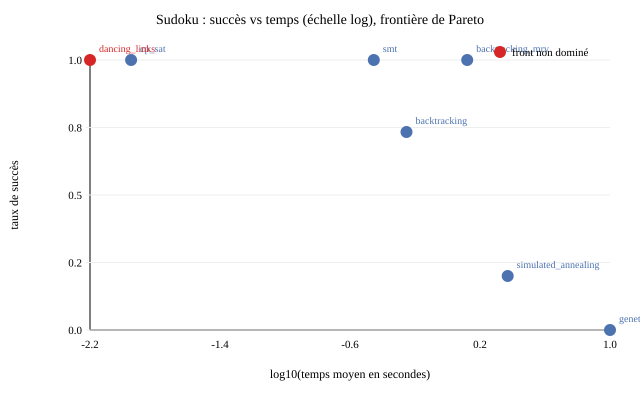

In [6]:
// Figure statique en SVG inline : le tracé est écrit à la main, aucune dépendance graphique.
public sealed class Svg
{
    public string Content;
    public Svg(string content) { Content = content; }
}

Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Svg>((value, context) =>
{
    context.Writer.Write(value.Content);
    return true;
}, "image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Svg), new[] { "image/svg+xml" });

var sudokuProf = profiles["sudoku"];
var sudokuAlts = FromProfiles(sudokuProf, ("success_rate", true), ("mean_time", false));
var sudokuFront = NonDominated(sudokuAlts, new[] { true, false });

double xMin = Math.Log10(sudokuProf.Min(p => p.MeanTime));
double xMax = Math.Log10(sudokuProf.Max(p => p.MeanTime));
double X(double t) => 90 + 520 * (Math.Log10(t) - xMin) / (xMax - xMin);
double Y(double s) => 330 - 270 * s;
string P(double v) => v.ToString("F1", CultureInfo.InvariantCulture);

var svg = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='640' height='400' viewBox='0 0 640 400'><rect width='640' height='400' fill='white'/>");
svg.Append("<text x='320' y='24' text-anchor='middle' font-size='14'>Sudoku : succès vs temps (échelle log), frontière de Pareto</text>");
svg.Append("<line x1='90' y1='330' x2='610' y2='330' stroke='black'/><line x1='90' y1='60' x2='90' y2='330' stroke='black'/>");
for (int d = 0; d <= 100; d += 25)
    svg.Append($"<text x='{P(90 + 520 * d / 100.0)}' y='348' text-anchor='middle' font-size='11'>{N(xMin + (xMax - xMin) * d / 100.0, "F1")}</text>");
for (int s = 0; s <= 4; s++)
{
    double v = s / 4.0;
    svg.Append($"<line x1='86' y1='{P(Y(v))}' x2='610' y2='{P(Y(v))}' stroke='#eeeeee'/>");
    svg.Append($"<text x='82' y='{P(Y(v) + 4)}' text-anchor='end' font-size='11'>{P(v)}</text>");
}
svg.Append("<text x='350' y='378' text-anchor='middle' font-size='12'>log10(temps moyen en secondes)</text>");
svg.Append("<text x='18' y='195' transform='rotate(-90 18 195)' text-anchor='middle' font-size='12'>taux de succès</text>");

var frontOrdered = sudokuFront.OrderBy(a => a.Objectives[1]).ToList();
if (frontOrdered.Count > 1)
{
    var poly = string.Join(" ", frontOrdered.Select(a => $"{P(X(a.Objectives[1]))},{P(Y(a.Objectives[0]))}"));
    svg.Append($"<polyline points='{poly}' fill='none' stroke='#d62728' stroke-width='2' stroke-dasharray='6 4'/>");
}
bool OnFront(string name) => frontOrdered.Any(a => a.Name == name);
foreach (var p in sudokuProf)
{
    string fill = OnFront(p.Paradigm) ? "#d62728" : "#4c72b0";
    svg.Append($"<circle cx='{P(X(p.MeanTime))}' cy='{P(Y(p.SuccessRate))}' r='6' fill='{fill}'/>");
    svg.Append($"<text x='{P(X(p.MeanTime) + 9)}' y='{P(Y(p.SuccessRate) - 8)}' font-size='10' fill='{fill}'>{p.Paradigm}</text>");
}
svg.Append("<circle cx='500' cy='52' r='6' fill='#d62728'/><text x='512' y='56' font-size='11'>front non dominé</text>");
svg.Append("</svg>");

display(new Svg(svg.ToString()));

La figure ne fait qu'**illustrer** le tableau précédent : le tracé rouge est le front non dominé, les autres points sont dominés sur le couple (succès, temps). Une frontière qui ne contient qu'un point signifie qu'aucun compromis n'existe sur ce jeu — c'est un résultat, pas un podium. C'est précisément ce que l'exercice suivant demande de généraliser.

### Exercice 2 (stub) — Pareto à trois objectifs

Étendre la comparaison à **3 objectifs** (succès, temps, mémoire) et retourner le front correspondant. `NonDominated` gère déjà un nombre arbitraire d'objectifs : le travail est d'ajouter le troisième et de vérifier que la colonne existe.

In [7]:
// INDICE :
//  - NonDominated accepte DÉJÀ un nombre arbitraire d'objectifs (le tableau `maximize`).
//  - il suffit d'ajouter mean_mem comme troisième objectif (min).
//  - vérifiez que la colonne existe dans le profil avant de l'ajouter.
static List<Alternative> Pareto3D(List<ProfileRow> prof, bool useMemory = true)
{
    var spec = new List<(string Col, bool Max)> { ("success_rate", true), ("mean_time", false) };
    if (useMemory) spec.Add(("mean_mem", false));   // ÉTAPE : ajouter la mémoire
    return new List<Alternative>();                 // TODO : déléguer à NonDominated (voir indices)
}

// --- Test : front à trois objectifs sur Sudoku ---
// var f3 = Pareto3D(profiles["sudoku"]);
// foreach (var a in f3) Console.WriteLine($"{a.Name} succès={N(a.Objectives[0])} temps={N(a.Objectives[1])} mémoire={N(a.Objectives[2])}");
Console.WriteLine("Exercice 2 (stub) — à compléter pour un front de Pareto à trois objectifs.");

Exercice 2 (stub) — à compléter pour un front de Pareto à trois objectifs.


## 5. Sélection sous préférences : le coût du choix

Le front de Pareto restreint les candidats, mais ne **décide pas** : il faut **arbitrer**. C'est le cœur du problème de **Rice** — à un ensemble d'instances et un choix d'objectifs, on associe l'algorithme qui **satisfait le mieux les préférences** du décideur.

On normalise chaque objectif *dans* son jeu (0 = pire, 1 = meilleur), puis on pondère selon 4 profils de préférence. Le **gagnant change** selon les poids : il n'existe pas de solveur universellement meilleur (écho du **No Free Lunch**). Deux précautions sont codées explicitement : on **écarte les candidats non viables** (succès 0, qui ne résolvent rien) et on **exclut la qualité** pour Sudoku (fitness partielle d'échec).

In [8]:
/// Normalise un vecteur dans [0,1], « mieux = plus haut » selon le sens demandé.
static double[] Norm01(double[] values, bool maximize)
{
    double lo = values.Min(), hi = values.Max();
    if (hi == lo) return values.Select(_ => 1.0).ToArray();
    return values.Select(v => maximize ? (v - lo) / (hi - lo) : (hi - v) / (hi - lo)).ToArray();
}

/// Classe les familles par score additif pondéré. useQuality=false exclut la qualité
/// (Sudoku : fitness partielle d'échec, pas une qualité de solution).
static List<(string Paradigm, double Score)> WeightedRanking(
    List<ProfileRow> prof, Dictionary<string, double> weights, bool qualityMax = true, bool useQuality = true)
{
    var w = new Dictionary<string, double> { ["success"] = 0, ["speed"] = 0, ["mem"] = 0, ["quality"] = 0 };
    foreach (var kv in weights) w[kv.Key] = kv.Value;

    var score = new double[prof.Count];
    void Accum(Func<ProfileRow, double> col, double weight, bool maximize)
    {
        if (weight == 0) return;
        var norm = Norm01(prof.Select(col).ToArray(), maximize);
        for (int i = 0; i < score.Length; i++) score[i] += weight * norm[i];
    }
    Accum(p => p.SuccessRate, w["success"], true);
    Accum(p => p.RelTime, w["speed"], true);
    Accum(p => p.RelMem, w["mem"], true);
    if (useQuality && prof.Any(p => p.HasQuality))
        Accum(p => p.MeanQuality, w["quality"], qualityMax);

    return prof.Select((p, i) => (Paradigm: p.Paradigm, Score: score[i]))
               .OrderByDescending(x => x.Score)
               .ToList();
}

// Spécification par jeu : sens de la qualité + pertinence comme objectif.
var gameSpec = new Dictionary<string, (bool QualityMax, bool UseQuality)>
{
    ["sudoku"] = (true, false),
    ["connect_four"] = (true, true),
    ["wordle"] = (false, true)
};

var weightSets = new Dictionary<string, Dictionary<string, double>>
{
    ["rapidite"] = new Dictionary<string, double> { ["success"] = 0.2, ["speed"] = 0.6, ["mem"] = 0.1, ["quality"] = 0.1 },
    ["memoire"] = new Dictionary<string, double> { ["success"] = 0.2, ["speed"] = 0.1, ["mem"] = 0.6, ["quality"] = 0.1 },
    ["robustesse"] = new Dictionary<string, double> { ["success"] = 0.7, ["speed"] = 0.1, ["mem"] = 0.1, ["quality"] = 0.1 },
    ["qualite"] = new Dictionary<string, double> { ["success"] = 0.2, ["speed"] = 0.1, ["mem"] = 0.1, ["quality"] = 0.6 }
};

foreach (var g in games)
{
    var spec = gameSpec[g];
    var pr = profiles[g];
    // Candidats viables : un solveur qui échoue sur 100 % des instances n'est pas
    // un candidat réel de sélection (il ne résout rien).
    var viable = pr.Where(p => p.SuccessRate > 0).ToList();
    Console.WriteLine($"===== {g} : gagnant sous chaque profil de préférence (candidats viables) =====");
    foreach (var kv in weightSets)
    {
        var r = WeightedRanking(viable, kv.Value, spec.QualityMax, spec.UseQuality);
        string extra = string.Join(" | ", r.Skip(1).Take(2).Select((x, i) => $"{i + 2}e: {x.Paradigm}"));
        Console.WriteLine($"  {kv.Key,-11} -> {r[0].Paradigm,-22} (score {N(r[0].Score)})" + (extra.Length > 0 ? " |  " + extra : ""));
    }
    var exclus = pr.Select(p => p.Paradigm).Except(viable.Select(p => p.Paradigm)).OrderBy(x => x, StringComparer.Ordinal);
    if (exclus.Any()) Console.WriteLine("  [exclus, succès=0] : " + string.Join(", ", exclus));
    Console.WriteLine();
}

===== sudoku : gagnant sous chaque profil de préférence (candidats viables) =====


  rapidite    -> dancing_links          (score 0.894) |  2e: cp_sat | 3e: backtracking_mrv


  memoire     -> dancing_links          (score 0.861) |  2e: backtracking_mrv | 3e: backtracking


  robustesse  -> dancing_links          (score 0.894) |  2e: backtracking_mrv | 3e: cp_sat


  qualite     -> dancing_links          (score 0.394) |  2e: backtracking_mrv | 3e: cp_sat


  [exclus, succès=0] : genetic


... (7 outputs left out)

  rapidite    -> bayesian_elimination   (score 0.915) |  2e: entropy | 3e: csp


  memoire     -> bayesian_elimination   (score 0.915) |  2e: entropy | 3e: csp


  robustesse  -> bayesian_elimination   (score 0.915) |  2e: entropy | 3e: csp


  qualite     -> entropy                (score 0.897) |  2e: bayesian_elimination | 3e: csp


**Résultat clé.** Aucun paradigme n'est le « meilleur » en toutes circonstances :

- **Sudoku** — **Dancing Links** gagne sous **tous** les profils (succès 100 %, le plus rapide, mémoire légère) : sur ce problème, le front se réduit à un point et la dominance est nette. La « qualité » étant exclue, le profil « qualité » retombe sur le même gagnant. `genetic` est **écarté** (succès 0).
- **Puissance 4** — un **vrai arbitrage** apparaît : `minimax` gagne mémoire/robustesse/qualité (qualité la plus haute), `alpha_beta` gagne **rapidité** (plus rapide à succès comparable). `baseline` et `MCTS` sont **écartés** (succès 0). C'est ici que le coût du choix est tangible.
- **Wordle** — `bayesian_elimination` gagne rapidité/mémoire/robustesse ; `entropy` gagne **qualité** (le moins de coups). Le **CSP** est dominé sur ce couple. Le basculement vitesse↔qualité est le plus lisible.

**Le coût du choix** est dès lors explicite : la « meilleure solution » dépend de *qui* décide et de *ce qu'il privilégie* — et la décision de **quels objectifs** inclure est elle-même un choix de modélisation (cœur du problème de **Rice**).

Une petite analyse de sensibilité rend ce point mesurable : sur Wordle, faisons varier continûment le poids de la qualité, les autres poids se partageant le reste dans des proportions fixes.

In [9]:
/// Analyse de sensibilité (Wordle) : le poids du nombre de coups (« qualité »)
/// croît de 0 à 1 pendant que les autres objectifs gardent leurs proportions
/// relatives — on relève le gagnant à chaque pas. Les points de bascule disent
/// où le verdict change ; une moyenne de poids les cacherait.
var wordleViable = profiles["wordle"].Where(p => p.SuccessRate > 0).ToList();
var sensitivity = new List<(double QualityWeight, string Winner)>();
for (int step = 0; step <= 20; step++)
{
    double qw = step / 20.0;
    double rest = 1 - qw;
    var weights = new Dictionary<string, double>
    {
        ["success"] = 0.5 * rest,
        ["speed"] = 0.3 * rest,
        ["mem"] = 0.2 * rest,
        ["quality"] = qw
    };
    sensitivity.Add((qw, WeightedRanking(wordleViable, weights, qualityMax: false, useQuality: true)[0].Paradigm));
}

Console.WriteLine("Wordle — gagnant selon le poids accordé au nombre de coups :");
foreach (var grp in sensitivity.GroupBy(x => x.Winner).OrderBy(g => g.Key, StringComparer.Ordinal))
    Console.WriteLine($"  {grp.Key,-24} min={N(grp.Min(x => x.QualityWeight), "F2")}  max={N(grp.Max(x => x.QualityWeight), "F2")}  count={grp.Count()}");
Console.WriteLine();
Console.WriteLine("Points de bascule :");
string previous = null;
foreach (var row in sensitivity)
{
    if (row.Winner != previous)
        Console.WriteLine($"  poids_qualite={N(row.QualityWeight, "F2")}  gagnant={row.Winner}");
    previous = row.Winner;
}

Wordle — gagnant selon le poids accordé au nombre de coups :


  bayesian_elimination     min=0.00  max=0.25  count=6


  entropy                  min=0.30  max=1.00  count=15


Points de bascule :


  poids_qualite=0.00  gagnant=bayesian_elimination


  poids_qualite=0.30  gagnant=entropy


**Interprétation.** Le point de bascule n'est pas une propriété naturelle de Wordle : il dépend de la normalisation et des proportions retenues entre succès, vitesse et mémoire. C'est précisément pourquoi [DecInfer-03](../../Probas/DecisionTheory/DecInfer/DecInfer-03-Multi-Attribute.ipynb) enseigne l'élicitation et la sensibilité des poids, et pourquoi le score doit rester une décision documentée plutôt qu'un podium.

### Exercice 3 (stub) — sélecteur leave-one-family-out

Tester la **robustesse** du choix : si on **retire** une famille du banc, le gagnant change-t-il ? Un sélecteur qui dépend d'un seul « outsider » est fragile.

In [10]:
// INDICE :
//  - profiles[g] est une liste de ProfileRow, une ligne par famille.
//  - retirer une famille = filtrer ses lignes puis relancer WeightedRanking.
//  - comparer le gagnant avec et sans la famille retirée, pour chaque jeu de poids.
static string LeaveOneFamilyOut(List<ProfileRow> prof, Dictionary<string, double> weights,
                                bool qualityMax = true, string family = null)
{
    IEnumerable<ProfileRow> cand = prof;
    if (family != null) cand = prof.Where(p => p.Paradigm != family);   // ÉTAPE : exclure la famille
    return null;   // TODO : implémenter (retourne le gagnant sans `family`)
}

// --- Test : le gagnant de "rapidite" sur Wordle change-t-il si on retire l'entropie ? ---
// Console.WriteLine("Gagnant 'rapidite' sans entropy : " + LeaveOneFamilyOut(profiles["wordle"], weightSets["rapidite"], qualityMax: false, family: "entropy"));
Console.WriteLine("Exercice 3 (stub) — à compléter pour un sélecteur leave-one-family-out.");

Exercice 3 (stub) — à compléter pour un sélecteur leave-one-family-out.


## 6. Traçabilité : de la question étudiante au cadre pédagogique

Le tableau ci-dessous relie **la question que se posait l'étudiant**, **l'appareil** qu'il a construit, **le résultat que ce carnet reproduit**, et l'**extension pédagogique** que CoursIA en tire. Les deux carnets (Python et C#) lisent les mêmes CSV : les résultats reproduits doivent coïncider.

In [11]:
/// Table de traçabilité : pour chaque question posée en TD, l'appareil
/// expérimental qui y répond, le résultat reproduit dans ce carnet, et
/// l'extension conceptuelle au-delà de la réponse immédiate — la synthèse
/// « que répond ce notebook » en une seule vue.
var trace = new (string Question, string Appareil, string Resultat, string Extension)[]
{
    ("Quelle famille est la plus rapide sur Sudoku ?",
     "Protocole commun (instances, timeouts 120 s, parallélisation)",
     "Dancing Links et CP-SAT dominent ; les métaheuristiques échouent",
     "La sélection d'algorithmes (Rice) a un coût empirique"),
    ("Les métriques sont-elles comparables entre paradigmes ?",
     "Colonnes uniformes time / mem / nodes par solveur",
     "nodes_explored non commensurable (CP-SAT≈55, GA≈400k)",
     "Non-commensurabilité = cas d'école des attributs d'instance"),
    ("Un classement unique est-il légitime ?",
     "Tables de résultats results/*.csv + notebook d'analyse",
     "Front de Pareto + gagnant dépendant des poids (§4-5)",
     "Un podium unique efface les compromis (Pareto)"),
    ("Quel solveur pour Puissance 4 en recherche adverse ?",
     "minimax / alpha-beta / MCTS / baseline, tournoi round-robin",
     "alpha-beta ~ minimax ~67 % ; MCTS / baseline 0 %",
     "Choix d'objectifs = décision de modélisation, pas un fait"),
    ("Wordle : information vs contraintes, qui gagne ?",
     "élimination bayésienne / entropie / CSP sur listes de mots",
     "historique + 45 runs frais sur 3 instances Wordle",
     "Dispersion, cache froid et stochasticité deviennent observables"),
    ("Que peut-on conclure au-delà d'une moyenne ?",
     "instance_id partagé dans les CSV historiques",
     "IC inter-instance + bootstrap hiérarchique (Annexe B)",
     "Une observation, une répétition et une population ne se confondent pas"),
    ("Mesurer une performance revient-il à prouver un algorithme ?",
     "Solveurs exécutables et mesures empiriques",
     "Aucune certification déduite des chronos (Annexe D)",
     "Performance, correction et optimalité restent trois niveaux distincts")
};

foreach (var t in trace)
{
    Console.WriteLine("Q : " + t.Question);
    Console.WriteLine("   appareil   : " + t.Appareil);
    Console.WriteLine("   reproduit  : " + t.Resultat);
    Console.WriteLine("   extension  : " + t.Extension);
    Console.WriteLine();
}

Q : Quelle famille est la plus rapide sur Sudoku ?


   appareil   : Protocole commun (instances, timeouts 120 s, parallélisation)


   reproduit  : Dancing Links et CP-SAT dominent ; les métaheuristiques échouent


   extension  : La sélection d'algorithmes (Rice) a un coût empirique


Q : Les métriques sont-elles comparables entre paradigmes ?


   appareil   : Colonnes uniformes time / mem / nodes par solveur


... (18 outputs left out)

Q : Mesurer une performance revient-il à prouver un algorithme ?


   appareil   : Solveurs exécutables et mesures empiriques


   reproduit  : Aucune certification déduite des chronos (Annexe D)


   extension  : Performance, correction et optimalité restent trois niveaux distincts


## Conclusion

Le benchmark de **Théodore Deguest** est plus qu'un comparatif : c'est un **appareil de mesure de la sélection d'algorithmes**. Quatre leçons s'en dégagent quand on l'associe au cadre de **Rice** et au **No Free Lunch** :

1. **La comparabilité se construit.** Provenance vérifiée, schéma validé, normalisation intra-jeu : rien n'est « naturellement » comparable entre un nœud de Dancing Links, une décision CP-SAT et une simulation MCTS.
2. **Un classement unique est un choix caché.** La frontière de Pareto révèle des compromis qu'un score agrégé écrase ; le gagnant dépend des **préférences** du décideur (§5).
3. **L'incertitude doit nommer ce qu'elle ré-échantillonne.** Les CSV historiques quantifient la diversité des instances ; les 45 runs Wordle ajoutent une petite fenêtre sur la dispersion inter-seed, avec cache froid contrôlé. Aucun des deux protocoles ne prétend remplacer une campagne confirmatoire.
4. **Mesurer, choisir et certifier sont trois gestes.** Les résultats empiriques orientent un choix ; les carnets Lean explicitent des garanties sous hypothèses distinctes ; aucun chrono ne certifie le code de Théodore et aucune preuve abstraite ne garantit le meilleur temps observé.

**À retenir de l'hommage :** le geste étudiant (faire courir ensemble des paradigmes hétérogènes sur un protocole honnête) est conservé, attribué, reproduit et **élevé** en cas d'application du problème de sélection d'algorithmes.

**Ce que le jumeau C# ajoute.** Le même résultat, obtenu sans `pandas` ni `numpy` : lecture CSV, agrégation, dominance, normalisation et bootstrap tiennent en quelques dizaines de lignes lisibles. C'est une démonstration de plus que le cadre de Rice ne dépend d'aucune bibliothèque — il dépend du **choix des attributs** et de la **documentation des préférences**.

## Annexe A — Objectifs et compétences visées

1. **Reconnaître** un appareil de mesure expérimental étudiant (protocole commun, métriques uniformes, timeouts, checkpoints).
2. **Établir** la provenance et le schéma des données avant toute analyse.
3. **Démontrer** que `nodes_explored`, `time_seconds` et `solution_quality` ne sont **pas commensurables** entre familles (Annexe C).
4. **Quantifier** la dispersion inter-instance et multi-seed, sans confondre ces deux sources d'incertitude (Annexe B).
5. **Calculer** des profils et des **frontières de Pareto** intra-jeu, sans podium global fallacieux (§3 et §4).
6. **Relier** la sélection de solveur au cadre de **Rice** et à la décision multi-attribut, puis tester la sensibilité aux préférences (§5).
7. **Séparer** performance empirique et garantie formelle grâce à des ponts Lean ciblés (Annexe D).

## Annexe B — Une moyenne n'est pas une preuve : deux niveaux d'incertitude

[Sudoku-18b](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb) distingue le bruit du système, la variance entre puzzles, l'intervalle bootstrap et les tests appariés. Appliquons cette discipline aux données de Théodore.

### B.1 — Incertitude inter-instance dans les CSV historiques

Les CSV contiennent une mesure par couple `paradigm × instance_id`, mais les **mêmes instances** sont bien partagées : 30 pour tous les solveurs Sudoku, 40 pour Wordle, et au moins 6 pour Puissance 4. Nous pouvons donc bootstrapper les **instances** pour quantifier l'incertitude sur ce panel. Cet intervalle ne mesure pas le bruit runtime d'une même instance et ne crée pas artificiellement des répétitions.

Le bootstrap utilise un générateur **SplitMix64** déterministe (graine 2026) plutôt qu'un RNG de bibliothèque : les intervalles sont reproductibles à l'octet près, et le percentile est calculé par interpolation linéaire.

In [12]:
/// Générateur déterministe SplitMix64 : reproductible, sans dépendance externe.
public sealed class Rng
{
    ulong state;
    public Rng(ulong seed) { state = seed; }
    public ulong NextULong()
    {
        state += 0x9E3779B97F4A7C15UL;
        ulong z = state;
        z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9UL;
        z = (z ^ (z >> 27)) * 0x94D049BB133111EBUL;
        return z ^ (z >> 31);
    }
    public int NextInt(int n) => (int)(NextULong() % (ulong)n);
}

/// Percentile par interpolation linéaire (convention numpy 'linear').
static double Percentile(double[] sorted, double q)
{
    double pos = (sorted.Length - 1) * q / 100.0;
    int lo = (int)Math.Floor(pos), hi = (int)Math.Ceiling(pos);
    return sorted[lo] + (sorted[hi] - sorted[lo]) * (pos - lo);
}

static (double Obs, double Lo, double Hi) BootstrapCI(
    double[] values, Func<double[], double> stat, int nBoot = 4000, ulong seed = 2026)
{
    var rng = new Rng(seed);
    var draws = new double[nBoot];
    var sample = new double[values.Length];
    for (int b = 0; b < nBoot; b++)
    {
        for (int i = 0; i < sample.Length; i++) sample[i] = values[rng.NextInt(values.Length)];
        draws[b] = stat(sample);
    }
    Array.Sort(draws);
    return (stat(values), Percentile(draws, 2.5), Percentile(draws, 97.5));
}

static double Median(double[] v)
{
    var s = (double[])v.Clone();
    Array.Sort(s);
    int n = s.Length;
    return n % 2 == 1 ? s[n / 2] : 0.5 * (s[n / 2 - 1] + s[n / 2]);
}

Console.WriteLine("Couverture et IC bootstrap 95 % inter-instance (médiane du temps, taux de succès) :");
foreach (var game in games)
{
    Console.WriteLine();
    Console.WriteLine($"===== {game} =====");
    var df = frames[game];
    var perFam = Enumerable.Range(0, df.Rows.Count)
        .GroupBy(i => df.Rows[i][df.Col("paradigm")])
        .OrderBy(g => g.Key, StringComparer.Ordinal)
        .ToList();
    var common = perFam
        .Select(g => g.Select(i => df.Rows[i][df.Col("instance_id")]).ToHashSet())
        .Aggregate((a, b) => { a.IntersectWith(b); return a; });
    Console.WriteLine($"instances communes à toutes les familles : {common.Count}");
    foreach (var grp in perFam)
    {
        var idx = grp.ToArray();
        var times = idx.Select(i => df.Num(i, "time_seconds")).ToArray();
        var succ = idx.Select(i => df.Bool(i, "success")).ToArray();
        var (med, loT, hiT) = BootstrapCI(times, Median);
        var (suc, loS, hiS) = BootstrapCI(succ, a => a.Average());
        Console.WriteLine($"  {grp.Key,-24} n={idx.Length,2} | succès={N(suc, "F2")} [{N(loS, "F2")}; {N(hiS, "F2")}]"
                        + $" | temps médian={med.ToString("G4", CultureInfo.InvariantCulture)}"
                        + $" [{loT.ToString("G4", CultureInfo.InvariantCulture)}; {hiT.ToString("G4", CultureInfo.InvariantCulture)}]");
    }
}

Couverture et IC bootstrap 95 % inter-instance (médiane du temps, taux de succès) :


===== sudoku =====


instances communes à toutes les familles : 30


  backtracking             n=30 | succès=0.73 [0.57; 0.87] | temps médian=0.4482 [0.04143; 0.7099]


  backtracking_mrv         n=30 | succès=1.00 [1.00; 1.00] | temps médian=0.04201 [0.01914; 0.1235]


  cp_sat                   n=30 | succès=1.00 [1.00; 1.00] | temps médian=0.01087 [0.007851; 0.01254]


... (11 outputs left out)

instances communes à toutes les familles : 40


  bayesian_elimination     n=40 | succès=1.00 [1.00; 1.00] | temps médian=0.003177 [0.002933; 0.003338]


  csp                      n=40 | succès=1.00 [1.00; 1.00] | temps médian=0.1099 [0.102; 0.1184]


  entropy                  n=40 | succès=1.00 [1.00; 1.00] | temps médian=6.865 [6.545; 7.527]


**Lecture honnête.** Les intervalles se resserrent quand les résultats sont homogènes et s'élargissent quand les instances discriminent davantage. Sur Puissance 4, les effectifs inégaux rendent la comparaison plus fragile : un test apparié à quatre familles devrait se limiter aux **6 instances communes**, et ne répondrait qu'à ce sous-panel. Nous n'en fabriquons pas ici un verdict universel.

### B.2 — Répétition fraîche multi-seed sur Wordle

Pour compléter les CSV historiques, CoursIA a rejoué le **code étudiant inchangé** sous WSL/Linux le 24 août 2026 : 3 instances de longueur 5, 3 solveurs, 5 graines, soit **45 mesures**. Le cache du premier coup entropique a été vidé avant chaque mesure : sans cela, un run froid suivi de runs chauds aurait produit une fausse accélération. Le protocole exact et la provenance sont consignés dans `data/app22-cross-paradigm/SOURCE.md`.

Cette petite expérience mesure deux choses distinctes : la variabilité **entre graines** pour les solveurs qui utilisent un RNG, et la variabilité **entre instances**. Elle n'est pas un nouveau benchmark exhaustif et ne remplace pas le corpus historique de mesures.

In [13]:
var repeated = Csv.Read(Path.Combine(DATA, "wordle_repeated_results.csv"));
Console.WriteLine($"lignes lues : {repeated.Rows.Count} (attendu 45)");
if (repeated.Rows.Count != 45) throw new InvalidOperationException("le fichier répété doit porter 45 mesures");

static double StdDev(double[] v)
{
    double m = v.Average();
    return Math.Sqrt(v.Sum(x => (x - m) * (x - m)) / (v.Length - 1));
}

/// Bootstrap hiérarchique : ré-échantillonner les instances, puis les graines en leur sein.
static (double Obs, double Lo, double Hi) HierarchicalCI(
    Frame df, int[] rows, string value, int nBoot = 4000, ulong seed = 2026)
{
    var rng = new Rng(seed);
    var byInstance = rows
        .GroupBy(i => df.Rows[i][df.Col("instance_id")])
        .ToDictionary(g => g.Key, g => g.Select(i => df.Num(i, value)).ToArray());
    var ids = byInstance.Keys.ToArray();
    double observed = rows.Average(i => df.Num(i, value));
    var draws = new double[nBoot];
    var buffer = new List<double>();
    for (int b = 0; b < nBoot; b++)
    {
        buffer.Clear();
        for (int s = 0; s < ids.Length; s++)
        {
            var pool = byInstance[ids[rng.NextInt(ids.Length)]];
            for (int k = 0; k < pool.Length; k++) buffer.Add(pool[rng.NextInt(pool.Length)]);
        }
        draws[b] = buffer.Average();
    }
    Array.Sort(draws);
    return (observed, Percentile(draws, 2.5), Percentile(draws, 97.5));
}

static double MedianOf(double[] v)
{
    var s = (double[])v.Clone();
    Array.Sort(s);
    int n = s.Length;
    return n % 2 == 1 ? s[n / 2] : 0.5 * (s[n / 2 - 1] + s[n / 2]);
}

var repGroups = Enumerable.Range(0, repeated.Rows.Count)
    .GroupBy(i => repeated.Rows[i][repeated.Col("paradigm")])
    .OrderBy(g => g.Key, StringComparer.Ordinal)
    .ToList();

Console.WriteLine("Wordle frais — 3 instances × 5 graines par solveur (IC hiérarchique 95 %) :");
foreach (var grp in repGroups)
{
    var idx = grp.ToArray();
    var (q, loQ, hiQ) = HierarchicalCI(repeated, idx, "solution_quality");
    var perInstanceSd = idx
        .GroupBy(i => repeated.Rows[i][repeated.Col("instance_id")])
        .Select(g => StdDev(g.Select(i => repeated.Num(i, "solution_quality")).ToArray()))
        .ToArray();
    double success = idx.Average(i => repeated.Bool(i, "success"));
    Console.WriteLine($"  {grp.Key,-24} succès={N(success, "F2")} | coups={N(q, "F2")} [{N(loQ, "F2")}; {N(hiQ, "F2")}]"
                    + $" | écart-type inter-seed médian={N(MedianOf(perInstanceSd), "F2")}");
}

Console.WriteLine();
Console.WriteLine("Contrôle déterminisme par instance (nombre de qualités distinctes sur 5 graines) :");
foreach (var grp in repGroups)
{
    var idx = grp.ToArray();
    var counts = idx
        .GroupBy(i => repeated.Rows[i][repeated.Col("instance_id")])
        .OrderBy(g => g.Key, StringComparer.Ordinal)
        .Select(g => g.Select(i => repeated.Num(i, "solution_quality")).Distinct().Count());
    Console.WriteLine($"  {grp.Key,-24} " + string.Join("  ", counts));
}

lignes lues : 45 (attendu 45)


Wordle frais — 3 instances × 5 graines par solveur (IC hiérarchique 95 %) :


  bayesian_elimination     succès=1.00 | coups=3.67 [3.27; 4.13] | écart-type inter-seed médian=0.71


  csp                      succès=1.00 | coups=4.20 [3.60; 4.87] | écart-type inter-seed médian=0.55


  entropy                  succès=1.00 | coups=3.33 [3.00; 4.00] | écart-type inter-seed médian=0.00


Contrôle déterminisme par instance (nombre de qualités distinctes sur 5 graines) :


  bayesian_elimination     2  3  3


  csp                      2  3  2


  entropy                  1  1  1


**Résultat reproductible, limite conservée.** Les 45 runs réussissent. L'entropie est déterministe à instance fixée (une qualité distincte pour chaque instance) ; l'élimination bayésienne et le CSP varient avec la graine. Avec seulement trois mots, les intervalles restent volontairement larges : ils démontrent la **dispersion**, pas une supériorité générale. Une étude confirmatoire devrait augmenter le nombre d'instances, isoler chaque processus, multiplier les machines ou répéter les temps après warm-up selon la question posée.

## Annexe C — `nodes_explored` : la même colonne, des unités différentes

Le piège le plus visible est la colonne `nodes_explored` : même nom, même type numérique… et **aucune commune mesure**. Un « nœud » n'est pas un nœud selon la famille :

- **Backtracking / MRV** et **Dancing Links** : un *nœud d'arbre de recherche* (case affectée / étape de couverture exacte). Comparables *entre eux*.
- **CP-SAT** : le solveur travaille par **propagation de contraintes et analyse de conflits** — les « nœuds » qu'il rapporte sont une **unité interne au solveur** (≈55 en moyenne ici), **pas** une énumération d'affectations.
- **SMT** : un *nombre de décisions* dans la procédure de décision.
- **GA / recuit simulé** : une *évaluation de fonction-objectif* (individu / état visité).
- **MCTS** : une *simulation de partie complète*.
- **Mot** (Wordle, élimination bayésienne / entropie) : un *candidat évalué* ; **CSP** (Wordle) : **`0`**.

On juxtapose la colonne brute, puis on s'interdit de la classer globalement.

In [14]:
/// Annexe C — pivot demandé : `nodes_explored` moyen par famille sur Sudoku.
/// La colonne existe dans les CSV mais ne compte pas le même travail selon
/// la famille : la lecture sous la table le dit, le chiffre seul ne le dit pas.
Console.WriteLine("Sudoku — `nodes_explored` moyen par famille :");
foreach (var p in profiles["sudoku"].OrderBy(x => x.MeanNodes))
    Console.WriteLine($"  {p.Paradigm,-24} {N(p.MeanNodes, "F1").PadLeft(12)}");
Console.WriteLine();
Console.WriteLine("Lecture : le CP-SAT rapporte ~55 'nœuds' internes (propagation/conflits),");
Console.WriteLine("le Wordle-CSP en rapporte 0, le backtracking ~804k d'énumération d'affectations,");
Console.WriteLine("le GA ~400k d'évaluations. Aucune de ces valeurs ne compte le même travail.");
Console.WriteLine("La colonne ne mesure PAS le même travail d'une famille à l'autre.");

Sudoku — `nodes_explored` moyen par famille :


  cp_sat                           55.5


  dancing_links                   217.3


  smt                            5936.9


  backtracking_mrv              91682.1


  simulated_annealing          248836.0


... (2 outputs left out)

Lecture : le CP-SAT rapporte ~55 'nœuds' internes (propagation/conflits),


le Wordle-CSP en rapporte 0, le backtracking ~804k d'énumération d'affectations,


le GA ~400k d'évaluations. Aucune de ces valeurs ne compte le même travail.


La colonne ne mesure PAS le même travail d'une famille à l'autre.


**Conséquence immédiate** : il est **mathématiquement invalide** de trier les 14 étiquettes de paradigme sur `nodes_explored`, ou de conclure « le solveur qui explore le moins est le meilleur ». Le notebook de l'étudiant le souligne déjà ; nous le formalisons ici comme un cas d'école du problème de **Rice** : les **attributs** d'une instance ne sont pas homogènes entre **espaces d'algorithmes**.

La **même** prudence vaut pour `time_seconds` (un solveur en pur Python vs un binding C++ natif) et pour `solution_quality` (voir §3). Toute normalisation doit donc être **intra-jeu** — jamais inter-jeu, jamais inter-famille de manière naïve.

## Annexe D — Mesurer, choisir, certifier : trois questions différentes

Le benchmark empirique répond à **« que s'est-il passé sur ces instances, avec cette machine et ce protocole ? »**. Il ne prouve ni la correction générale d'un solveur ni son optimalité. CoursIA permet de situer précisément ces niveaux :

| Niveau | Question | Pont CoursIA | Ce que le pont établit — et n'établit pas |
|---|---|---|---|
| **Performance empirique** | Quel solveur réussit, à quel coût observé ? | [Sudoku-18](../../Sudoku/Sudoku-18-Comparison-Python.ipynb), [Sudoku-18b](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb) | Comparaison et incertitude sur un protocole ; aucune preuve universelle. |
| **Correction / invariants** | Une étape de propagation conserve-t-elle les solutions ? | [Sudoku-19-Lean-Propagation-Lean](../../Sudoku/Sudoku-19-Lean-Propagation-Lean.ipynb) | Formalise des invariants de propagation ; **ne vérifie pas** les implémentations de Théodore. |
| **Optimalité conditionnelle** | Sous quelles hypothèses une stratégie est-elle optimale ? | [Search-03e-AStar-Optimality](../Part1-Foundations/Search-03e-AStar-Optimality.ipynb) | Prouve une optimalité sous hypothèses ; ne transforme pas un chrono en théorème. |
| **Valeur d'un jeu adverse** | Comment relier valeur minimax et stratégie ? | [GameTheory-05b-Lean-Minimax-Lean](../../GameTheory/GameTheory-05b-Lean-Minimax-Lean.ipynb) | Donne les fondations formelles de minimax ; ne certifie ni le moteur Puissance 4 ni ses performances. |
| **Décision** | Comment arbitrer entre attributs et coût d'information ? | [DecInfer-01b-Lean-ExpectedUtility](../../Probas/DecisionTheory/DecInfer/DecInfer-01b-Lean-ExpectedUtility.ipynb), [DecInfer-05](../../Probas/DecisionTheory/DecInfer/DecInfer-05-Value-Information.ipynb) | Formalise le langage du choix ; les poids et distributions restent à justifier empiriquement. |

Cette séparation évite deux confusions symétriques : **un solveur rapide n'est pas, pour cette raison, prouvé correct** ; **un algorithme prouvé correct ou optimal sous hypothèses n'est pas, pour cette raison, le plus rapide ici**.

## Annexe E — Limites honnêtes

Un hommage ne maquille pas les faiblesses : il les expose, car elles font partie de l'apport.

1. **Collecte Unix uniquement.** Le paquet étudiant `benchmark` importe `resource` et utilise `SIGALRM` pour les timeouts → la collecte des résultats **échoue sous Windows natif**. Les CSV livrés ont donc été produits sous **Unix**. C'est une **limite de portabilité** assumée, pas un défaut caché.
2. **Une seule observation historique par solveur × instance.** Les trois CSV étudiants permettent d'étudier la variabilité **entre instances**, pas le bruit d'exécution à instance fixée. Les IC bootstrap de l'Annexe B.1 ré-échantillonnent les instances ; ils ne doivent pas être lus comme des répétitions runtime.
3. **Répétition fraîche volontairement petite.** L'extension CoursIA Wordle porte sur 3 instances × 5 graines × 3 solveurs. Elle rend la dispersion visible, mais trois mots ne suffisent pas pour une conclusion confirmatoire.
4. **Effectifs inégaux sur Puissance 4.** Les familles couvrent 6 à 10 instances ; les quatre ne partagent que **6 `instance_id`**. Les taux et moyennes sont donc fragiles.
5. **Métriques hétérogènes.** `nodes_explored`, `solution_quality` et même `time_seconds` ne comparent pas la même chose d'une famille à l'autre (§3 et Annexe C). Les profils sont donc **intra-jeu**.
6. **Mémoire `ru_maxrss`.** Le pic mémoire est le `ru_maxrss` du **processus**, pas une allocation fine ; le GA/recuit allouent beaucoup et gonflent ce chiffre.
7. **Stochasticité partiellement caractérisée.** Le multi-seed Wordle montre que l'entropie est déterministe à instance fixée, tandis que l'élimination bayésienne et le CSP varient. GA, recuit et MCTS restent décrits par une seule observation historique par instance.
8. **Sous-ensemble de familles.** Le README étudiant précise : **6 paradigmes Sudoku** sur **17 possibles** ; **Choco** et les solveurs **neuronaux/LLM** ne sont pas implémentés. Le benchmark compare un **échantillon**, pas l'espace complet.
9. **Pas de généralisation universelle ni de certification implicite.** Le No Free Lunch interdit d'en déduire un dominateur universel ; les ponts Lean de l'Annexe D éclairent des propriétés formelles distinctes, sans vérifier le code étudiant.
10. **Écart de bibliothèques assumé (jumeau C#).** Les intervalles bootstrap ne sont pas identiques au carnet Python au chiffre près : le C# utilise son propre générateur déterministe (SplitMix64, graine 2026) là où Python appelle `numpy.default_rng(2026)`. Les **conclusions** (fronts, vainqueurs, points de bascule, directions d'intervalle) sont identiques ; les bornes numériques des IC diffèrent au troisième chiffre. C'est documenté plutôt que masqué.

Ces limites **renforcent** le propos : la comparabilité se **construit** (provenance, schéma, normalisation, Pareto) — elle n'est jamais donnée.

## Annexe F — Sources

- **Travail distillé** : Théodore Deguest, *« Benchmark cross-paradigme de solveurs de jeux »* — sujet L4, cours Intelligence Symbolique, EPITA SCIA. PR [#42](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/pull/42), projet [L4-Benchmark-Cross-Paradigm](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/tree/main/L4-Benchmark-Cross-Paradigm). Dépôt source sous **licence MIT** (copyright 2026, *The 2026-Epita-Intelligence-Symbolique contributors*). Données : `results/{sudoku,connect_four,wordle}_results.csv`.
- **Cadre théorique** :
  - **Rice, J. R. (1976)** — *« The Algorithm Selection Problem »*, Advances in Computers 15, pp. 65-118.
  - **Wolpert, D. H. & Macready, W. G. (1997)** — *« No Free Lunch Theorems for Optimization »*, IEEE Trans. on Evolutionary Computation 1(1), pp. 67-82.
- **Arc sélection et représentation** :
  - [MGS-15-LandscapeAnalysis](../Part4-Metaheuristics/MGS-15-LandscapeAnalysis.ipynb) → [MGS-16-AlgorithmSelection](../Part4-Metaheuristics/MGS-16-AlgorithmSelection.ipynb) → [MGS-21-Representation-vs-Algorithme](../Part4-Metaheuristics/MGS-21-Representation-vs-Algorithme.ipynb).
  - [App-10-Portfolio-Python](App-10-Portfolio-Python.ipynb), [App-18-HyperparameterTuning-Python](App-18-HyperparameterTuning-Python.ipynb) et [MGS-17-ParameterControl](../Part4-Metaheuristics/MGS-17-ParameterControl.ipynb).
- **Arc expérimental et décision** :
  - [Sudoku-18-Comparison-Python](../../Sudoku/Sudoku-18-Comparison-Python.ipynb) / [Sudoku-18b-Statistical-Comparison-Python](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb).
  - [DecInfer-03-Multi-Attribute](../../Probas/DecisionTheory/DecInfer/DecInfer-03-Multi-Attribute.ipynb) / [DecInfer-05-Value-Information](../../Probas/DecisionTheory/DecInfer/DecInfer-05-Value-Information.ipynb).
- **Terrains applicatifs** :
  - [App-20-SudokuBenchmark-Python](App-20-SudokuBenchmark-Python.ipynb), [App-12-ConnectFour-Python](App-12-ConnectFour-Python.ipynb), [App-14-ConnectFour-Adversarial-Python](App-14-ConnectFour-Adversarial-Python.ipynb), [App-07-Wordle-Python](App-07-Wordle-Python.ipynb).
- **Ponts formels, sans certification du code étudiant** :
  - [Sudoku-19-Lean-Propagation-Lean](../../Sudoku/Sudoku-19-Lean-Propagation-Lean.ipynb), [Search-03e-AStar-Optimality](../Part1-Foundations/Search-03e-AStar-Optimality.ipynb), [GameTheory-05b-Lean-Minimax-Lean](../../GameTheory/GameTheory-05b-Lean-Minimax-Lean.ipynb), [DecInfer-01b-Lean-ExpectedUtility](../../Probas/DecisionTheory/DecInfer/DecInfer-01b-Lean-ExpectedUtility.ipynb).